# From Data to Forecasts: live demo
DevFest Sherbrooke 2026 · Ontario hourly electricity demand, 24-hour-ahead forecasts on 2026

Reads the outputs of the full notebook (`artifacts/`): no training, every cell runs in seconds.

## Setup

In [6]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ARTIFACTS_URL = "https://raw.githubusercontent.com/FarahHammamii/devFest_Sherbrooke_Time_Series/main/artifacts"
FILES = ["ontario_demand.csv", "predictions.npz", "results.csv", "coverage.csv", "lstm.keras"]

os.makedirs("artifacts", exist_ok=True)
for f in FILES:
    if not os.path.exists(f"artifacts/{f}"):
        try:
            urllib.request.urlretrieve(f"{ARTIFACTS_URL}/{f}", f"artifacts/{f}")
        except Exception as e:
            print(f"missing {f}: {e}")

C = dict(actual="#1e1e1e", naive="#9aa0a6", seasonal="#fbbc04", linear="#34a853",
         lstm="#4285f4", qlstm="#ea4335", timesfm="#a142f4", band="#c3ecf6")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 13, "axes.titleweight": "bold"})
colors = {"Naive (last value)": C["naive"], "Same hour yesterday": C["seasonal"], "Same hour last week": C["seasonal"],
          "Linear (Keras)": C["linear"], "LSTM (Keras)": C["lstm"], "Quantile LSTM (P50)": C["qlstm"], "TimesFM (zero-shot)": C["timesfm"]}

try:
    df = pd.read_csv("artifacts/ontario_demand.csv", parse_dates=["time"], index_col="time")
except ValueError as e:
    print("Erreur lors de la lecture du CSV.")
    temp_df = pd.read_csv("artifacts/ontario_demand.csv", nrows=5)
    print("Colonnes trouvées dans le fichier :", list(temp_df.columns))
    raise e

z = np.load("artifacts/predictions.npz", allow_pickle=False)
names = list(z["names"])
preds = dict(zip(names, z["preds"]))
y_true, q_lstm, q_tfm = z["y_true"], z["q_lstm"], z["q_timesfm"]
test_times = pd.to_datetime(z["test_times"])
LOOKBACK, HORIZON = int(z["lookback"]), int(z["horizon"])

## 1 · Ontario demand, 2020–2026

60,169 hourly observations, 2020-01-01 to 2026-11-12


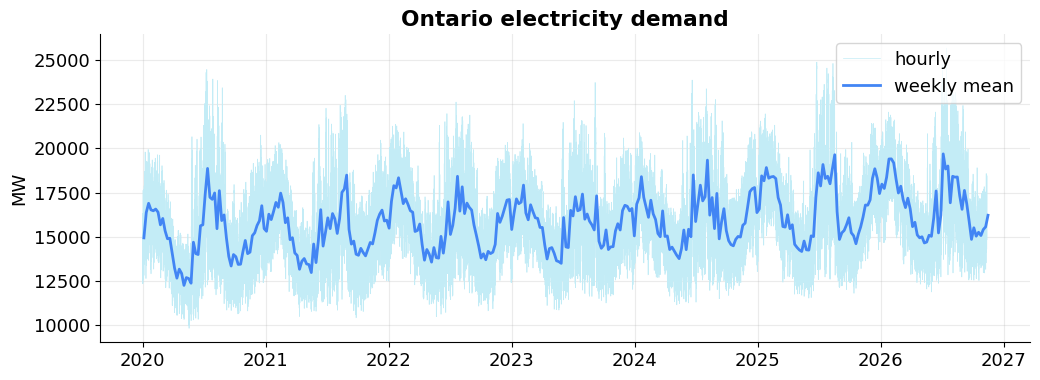

In [7]:
print(f"{len(df):,} hourly observations, {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
fig, ax = plt.subplots()
ax.plot(df.index, df["demand"], color=C["band"], lw=0.5, label="hourly")
ax.plot(df["demand"].resample("W").mean(), color=C["lstm"], lw=2, label="weekly mean")
ax.set(title="Ontario electricity demand", ylabel="MW"); ax.legend(loc="upper right")
plt.show()

## 2 · Seasonality

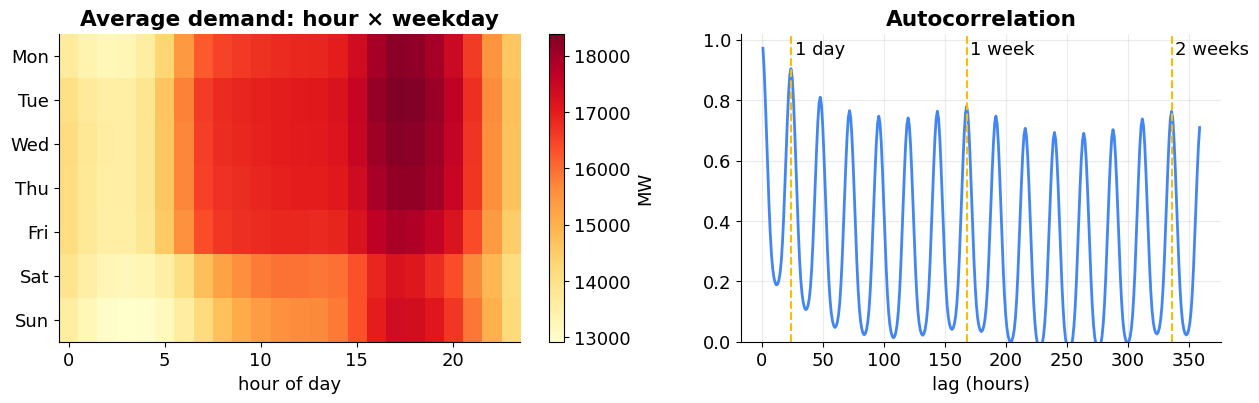

In [8]:
prof = df.assign(hour=df.index.hour, dow=df.index.day_name().str[:3]).pivot_table(
    index="dow", columns="hour", values="demand", aggfunc="mean").loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]
lags = np.arange(1, 24 * 15)
acf = np.array([df["demand"].autocorr(l) for l in lags])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.2, 1]})
im = a1.imshow(prof, aspect="auto", cmap="YlOrRd")
a1.set(yticks=range(7), yticklabels=prof.index, xlabel="hour of day", title="Average demand: hour × weekday")
a1.grid(False); fig.colorbar(im, ax=a1, label="MW")
a2.plot(lags, acf, color=C["lstm"], lw=2)
for l, txt in [(24, "1 day"), (168, "1 week"), (336, "2 weeks")]:
    a2.axvline(l, color=C["seasonal"], ls="--"); a2.text(l + 3, 0.95, txt)
a2.set(title="Autocorrelation", xlabel="lag (hours)", ylim=(0, 1.02))
plt.show()

## 3 · Chronological split and one window

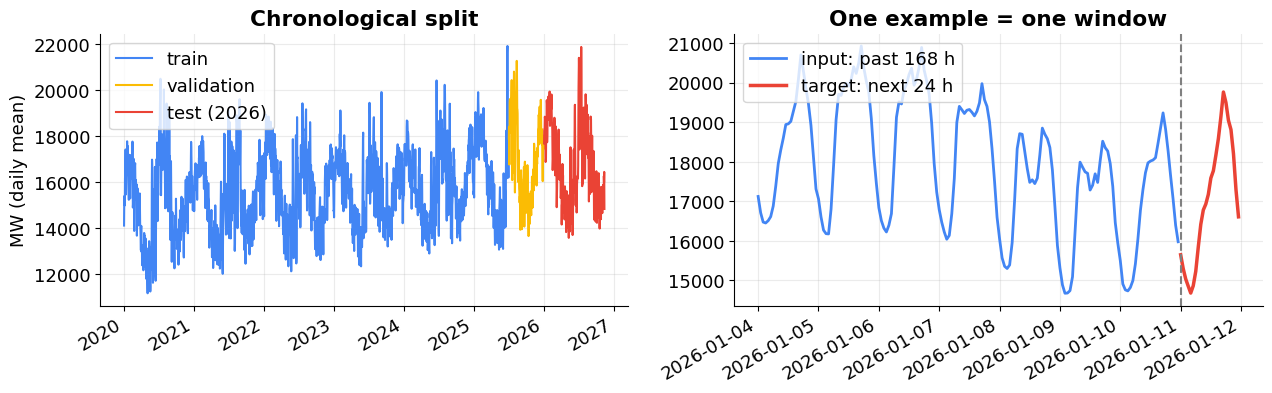

In [9]:
VAL_START, TEST_START = pd.Timestamp("2025-07-01"), pd.Timestamp("2026-01-01")
daily = df["demand"].resample("D").mean()
t0 = test_times[10]
past = df.loc[t0 - pd.Timedelta(hours=LOOKBACK): t0 - pd.Timedelta(hours=1), "demand"]
future = df.loc[t0: t0 + pd.Timedelta(hours=HORIZON - 1), "demand"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4))
for part, col, lab in [(daily[:VAL_START - pd.Timedelta(days=1)], C["lstm"], "train"),
                       (daily[VAL_START:TEST_START - pd.Timedelta(days=1)], C["seasonal"], "validation"),
                       (daily[TEST_START:], C["qlstm"], "test (2026)")]:
    a1.plot(part, color=col, lw=1.5, label=lab)
a1.set(title="Chronological split", ylabel="MW (daily mean)"); a1.legend(loc="upper left")
a2.plot(past, color=C["lstm"], lw=2, label="input: past 168 h")
a2.plot(future, color=C["qlstm"], lw=2.5, label="target: next 24 h")
a2.axvline(t0, color="grey", ls="--"); a2.set(title="One example = one window"); a2.legend(loc="upper left")
fig.autofmt_xdate(); plt.show()

## 4 · The LSTM (TensorFlow / Keras)
```python
model = keras.Sequential([
    keras.Input((168, 8)),
    keras.layers.LSTM(64),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(24),
])
model.compile("adam", loss="mae")
```

In [10]:
from tensorflow import keras
keras.models.load_model("artifacts/lstm.keras", compile=False).summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,408 (95.34 KB)

 Trainable params: 24,408 (95.34 KB)

 Non-trainable params: 0 (0.00 B)

## 5 · Scoreboard: test MAE on 2026

,MAE (MW),RMSE (MW),MAPE (%),vs last week (%)
Quantile LSTM (P50),530.4,728.5,3.1,53.9
Linear (Keras),549.8,767.9,3.2,52.2
LSTM (Keras),557.7,744.0,3.3,51.5
TimesFM (zero-shot),585.6,839.9,3.4,49.1
Same hour yesterday,810.6,1068.7,4.8,29.5
Same hour last week,1150.0,1545.8,6.8,0.0
Naive (last value),1722.6,2155.3,9.8,-49.8


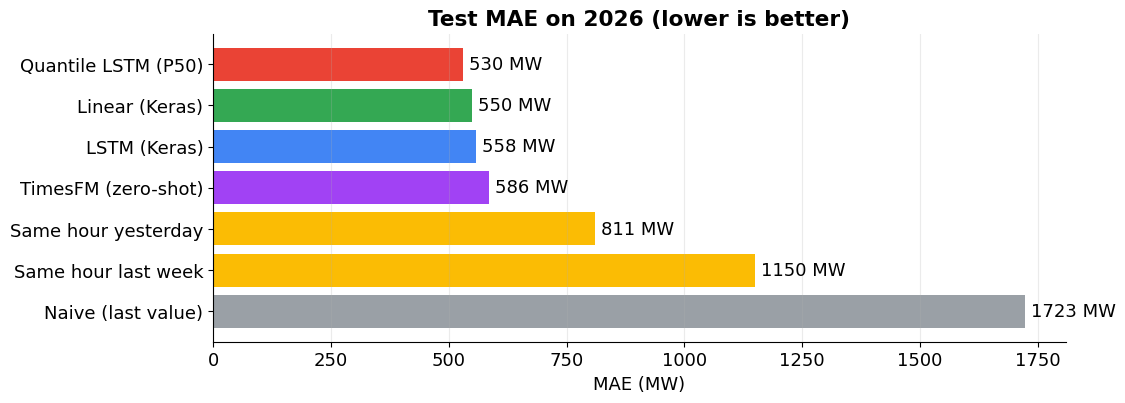

In [11]:
results = pd.read_csv("artifacts/results.csv", index_col=0)
display(results.round(1))
r = results["MAE (MW)"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.barh(r.index, r.values, color=[colors.get(k, "grey") for k in r.index])
ax.bar_label(bars, fmt="%.0f MW", padding=4)
ax.set(title="Test MAE on 2026 (lower is better)", xlabel="MAE (MW)"); ax.grid(axis="y", alpha=0)
plt.show()

## 6 · Where do models struggle?

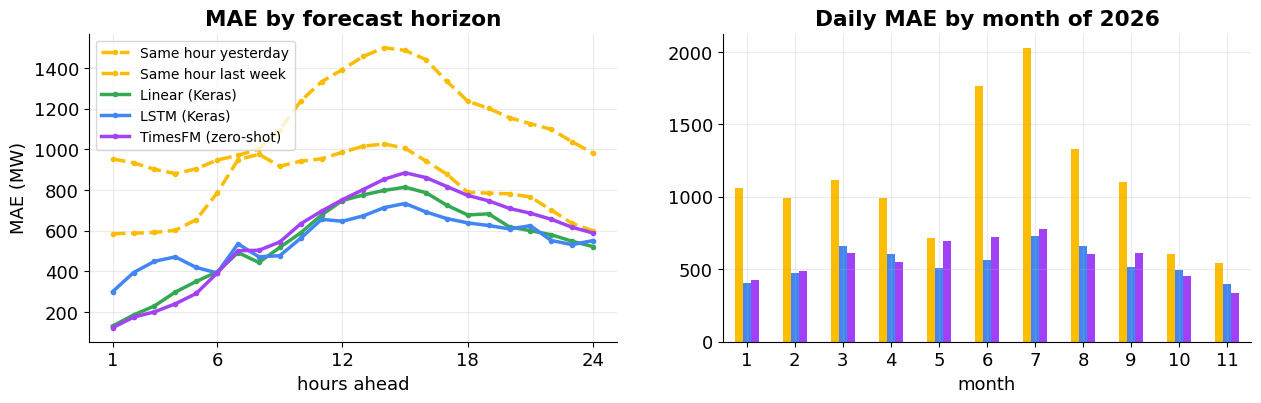

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4))
for k in ["Same hour yesterday", "Same hour last week", "Linear (Keras)", "LSTM (Keras)", "TimesFM (zero-shot)"]:
    if k in preds:
        a1.plot(range(1, HORIZON + 1), np.abs(preds[k] - y_true).mean(0), lw=2.5, color=colors[k],
                ls="--" if "Same" in k else "-", label=k, marker="o", ms=3)
a1.set(title="MAE by forecast horizon", xlabel="hours ahead", ylabel="MAE (MW)", xticks=[1, 6, 12, 18, 24]); a1.legend(fontsize=10)

cmp = [k for k in ["Same hour last week", "LSTM (Keras)", "TimesFM (zero-shot)"] if k in preds]
err = pd.DataFrame({k: np.abs(preds[k] - y_true).mean(1) for k in cmp}).groupby(test_times.month).mean()
err.plot.bar(ax=a2, color=[colors[k] for k in cmp], rot=0, legend=False)
a2.set(title="Daily MAE by month of 2026", xlabel="month")
plt.show()

## 7 · Uncertainty: P10–P90 band and coverage

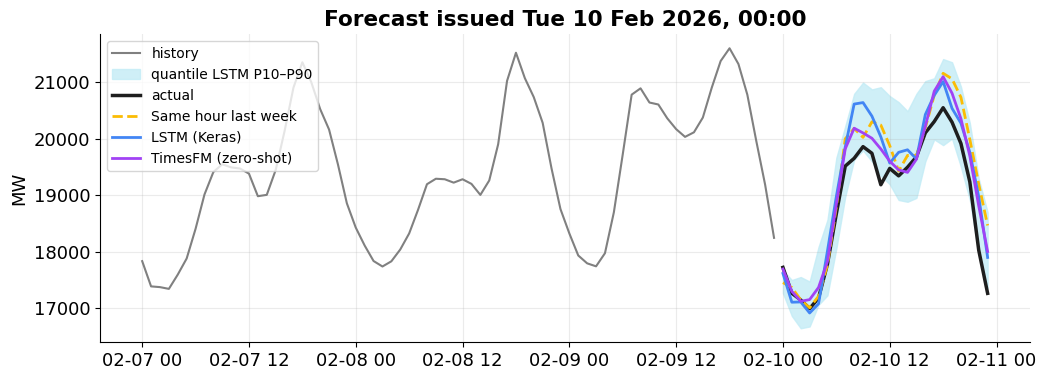

,coverage (%),mean width (MW)
Quantile LSTM,72.8,1534.5
TimesFM,76.3,1699.1


In [13]:
DAY = 40  # @param {type:"slider", min:0, max:300, step:1}
d = min(DAY, len(test_times) - 1)
t = test_times[d]
fut = pd.date_range(t, periods=HORIZON, freq="h")
hist = df.loc[t - pd.Timedelta(hours=72): t - pd.Timedelta(hours=1), "demand"]

fig, ax = plt.subplots()
ax.plot(hist, color="grey", lw=1.5, label="history")
ax.fill_between(fut, q_lstm[d, :, 0], q_lstm[d, :, 2], color=C["band"], alpha=0.8, label="quantile LSTM P10–P90")
ax.plot(fut, y_true[d], color=C["actual"], lw=2.5, label="actual")
for k in ["Same hour last week", "LSTM (Keras)", "TimesFM (zero-shot)"]:
    if k in preds:
        ax.plot(fut, preds[k][d], color=colors[k], lw=2, ls="--" if "Same" in k else "-", label=k)
ax.set(title=f"Forecast issued {t:%a %d %b %Y}, 00:00", ylabel="MW"); ax.legend(loc="upper left", fontsize=10)
plt.show()

display(pd.read_csv("artifacts/coverage.csv", index_col=0).round(1))

## 8 · TimesFM: zero-shot vs trained models

,MAE (MW),RMSE (MW),vs last week (%)
Same hour last week,1150.0,1545.8,0.0
Linear (Keras),549.8,767.9,52.2
LSTM (Keras),557.7,744.0,51.5
TimesFM (zero-shot),585.6,839.9,49.1


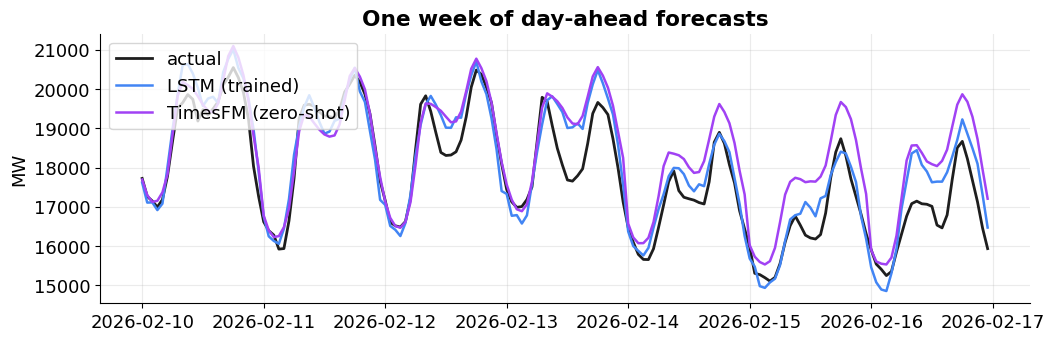

In [14]:
keep = [k for k in ["Same hour last week", "Linear (Keras)", "LSTM (Keras)", "TimesFM (zero-shot)"] if k in results.index]
display(results.loc[keep, ["MAE (MW)", "RMSE (MW)", "vs last week (%)"]].round(1))
if "TimesFM (zero-shot)" in preds:
    fig, ax = plt.subplots(figsize=(12, 3.5))
    days = slice(d, d + 7)
    span = pd.date_range(test_times[d], periods=7 * HORIZON, freq="h")
    ax.plot(span, y_true[days].ravel(), color=C["actual"], lw=2, label="actual")
    ax.plot(span, preds["LSTM (Keras)"][days].ravel(), color=C["lstm"], lw=1.8, label="LSTM (trained)")
    ax.plot(span, preds["TimesFM (zero-shot)"][days].ravel(), color=C["timesfm"], lw=1.8, label="TimesFM (zero-shot)")
    ax.set(title="One week of day-ahead forecasts", ylabel="MW"); ax.legend(loc="upper left")
    plt.show()